# DSC8307 – Project 2: Credit Card Fraud Detection
**Course:** DSC8307 — Data Mining, Modeling and Analytics  
**Programme:** Master of Science in Data Science and Analytics  
**Institution:** Uganda Christian University  
**Registration Number:** S25M19/013  
**Access Number:** B34983  
## Executive summary
This notebook builds and compares three transaction-ranking approaches: a robust statistical outlier baseline, an unsupervised cluster-based detector, and a supervised classification model. The task is to prioritise transactions for investigation, not simply classify them at an arbitrary threshold.



## 1. Problem formulation and method
The business objective is to rank transactions so investigators can review the riskiest cases first. Because fraud is extremely rare, accuracy is not an adequate headline metric: predicting every transaction as legitimate would still be approximately 99.83% accurate while detecting no fraud.

The analysis:
1. explores structure, quality, imbalance and feature distributions;
2. establishes a robust statistical outlier baseline;
3. fits MiniBatch K-Means on legitimate training transactions and scores test transactions by distance to the nearest centroid;
4. fits a class-weighted Random Forest using labelled training data;
5. evaluates all scores on the same held-out test transactions using Average Precision, ROC-AUC, precision@K and recall@K.

A stratified 70/30 split preserves fraud prevalence. Test labels are withheld during model fitting. Preprocessing is fitted on training data only. Statistical and cluster models learn the legitimate training profile; the classifier learns from both classes in training.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, roc_curve, confusion_matrix, classification_report)
from sklearn.metrics import pairwise_distances_argmin_min

DATA_PATH=Path("creditcard.csv")
if not DATA_PATH.exists(): DATA_PATH=Path("/mnt/data/creditcard.csv")
df=pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data exploration and data quality
The README indicates 28 PCA-derived predictors plus `Time` and `Amount`; `Class` is the response. The original meanings of the PCA variables are not disclosed, so they are treated as anonymous numeric inputs.

In [2]:
pca_cols=[f"V{i}" for i in range(1,29)]
feature_cols=pca_cols+["Time","Amount"]
required=feature_cols+["Class"]
missing_cols=sorted(set(required)-set(df.columns))
if missing_cols: raise ValueError(f"Missing columns: {missing_cols}")
print("Data types:"); display(df.dtypes.to_frame("dtype"))
print("Missing values:"); display(df.isna().sum().to_frame("missing"))
print("Duplicate rows:", int(df.duplicated().sum()))
counts=df.Class.value_counts().sort_index()
display(counts.rename(index={0:"Legitimate",1:"Fraud"}).to_frame("transactions"))
print(f"Fraud prevalence: {df.Class.mean():.4%}")

Data types:


,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


Missing values:


,missing
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Duplicate rows: 1081


,transactions
Class,
Legitimate,284315
Fraud,492


Fraud prevalence: 0.1727%


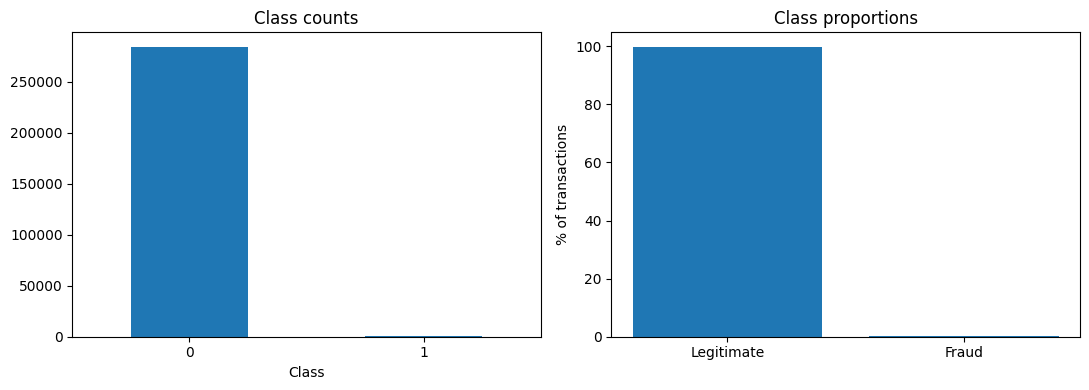

,count,mean,std,min,25%,50%,75%,max
V1,284807.0,0.00,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.0,0.00,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.0,-0.00,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.0,0.00,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.0,0.00,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.0,0.00,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.0,-0.00,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.0,0.00,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.0,-0.00,1.099,-13.434,-0.643,-0.051,0.597,15.595
V10,284807.0,0.00,1.089,-24.588,-0.535,-0.093,0.454,23.745


,skewness,unique
V1,-3.281,275663
V2,-4.625,275663
V3,-2.240,275663
V4,0.676,275663
V5,-2.426,275663
V6,1.827,275663
V7,2.554,275663
V8,-8.522,275663
V9,0.555,275663
V10,1.187,275663


In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
counts.plot(kind="bar",ax=ax[0],rot=0); ax[0].set_title("Class counts"); ax[0].set_xlabel("Class")
ax[1].bar(["Legitimate","Fraud"],[(df.Class==0).mean()*100,(df.Class==1).mean()*100])
ax[1].set_title("Class proportions"); ax[1].set_ylabel("% of transactions")
plt.tight_layout(); plt.show()
display(df[feature_cols].describe().T.round(3))
display(pd.DataFrame({"skewness":df[feature_cols].skew(),"unique":df[feature_cols].nunique()}).round(3))

The left panel shows the overwhelming dominance of legitimate transactions. The right panel expresses the same imbalance as percentages: fraud represents only about 0.172% of all transactions. This is why overall accuracy would be misleading as the main evaluation measure: a model could classify nearly everything as legitimate and still achieve very high accuracy while detecting few fraud cases.

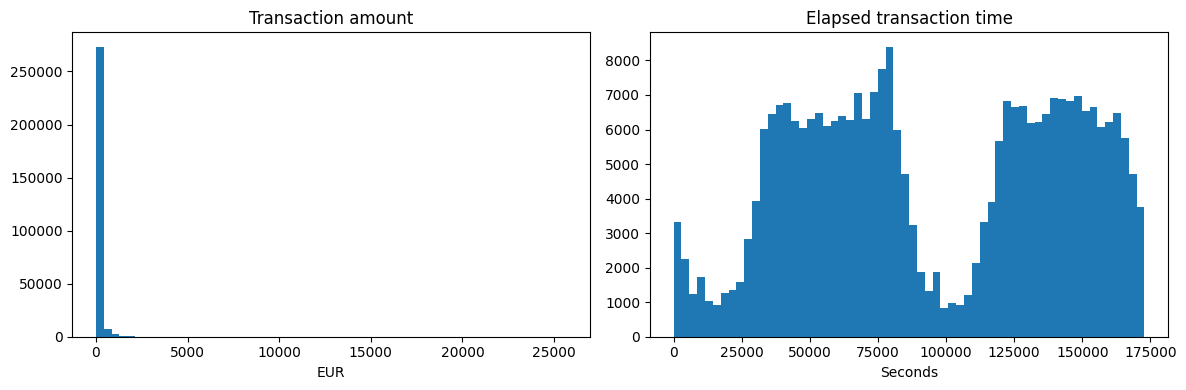

Amount                       Time                    
          mean median      std       mean   median        std
Class                                                        
0       88.291  22.00  250.105  94838.202  84711.0  47484.016
1      122.211   9.25  256.683  80746.807  75568.5  47835.365

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(df.Amount,bins=60); ax[0].set_title("Transaction amount"); ax[0].set_xlabel("EUR")
ax[1].hist(df.Time,bins=60); ax[1].set_title("Elapsed transaction time"); ax[1].set_xlabel("Seconds")
plt.tight_layout(); plt.show()
display(df.groupby("Class")[["Amount","Time"]].agg(["mean","median","std"]).round(3))

The amount histogram shows a concentration of transactions at relatively low values with a long upper tail. The elapsed-time histogram shows the distribution of transactions over the two-day observation period. The descriptive comparison in the notebook reports mean amount of 88.291 for legitimate transactions and 122.211 for fraud, while the medians are 22.00 and 9.25 respectively. The differing means and medians indicate skewness and show why averages alone do not describe typical transaction behaviour. These two variables were log1p-transformed before scaling.

## 3. Data preparation and split
`Amount` and `Time` are right-skewed/scaled differently from the PCA variables. `log1p` is applied to these two non-negative variables. The PCA components are retained as supplied. Median imputation (if needed) and standardisation are fitted on training data only. Exact duplicate rows are reported but not automatically removed because identical feature values do not prove duplicate transactions and no transaction identifier is supplied.

A stratified split is used to retain rare fraud cases in both partitions. The test labels are not used in fitting or model selection.

In [5]:
if df.Class.isna().any() or not set(df.Class.unique()).issubset({0,1}):
    raise ValueError("Class must be complete and coded 0/1.")
if (df[["Time","Amount"]]<0).any().any():
    raise ValueError("Negative Time/Amount values require investigation before log1p.")
Xraw=df[feature_cols].copy(); y=df.Class.astype(int)
Xtr_raw,Xte_raw,ytr,yte=train_test_split(Xraw,y,test_size=.30,random_state=42,stratify=y)
def transform(X):
    Z=X.copy()
    Z["Time"]=np.log1p(Z["Time"])
    Z["Amount"]=np.log1p(Z["Amount"])
    return Z
itr=SimpleImputer(strategy="median")
tr_i=itr.fit_transform(transform(Xtr_raw)); te_i=itr.transform(transform(Xte_raw))
sc=StandardScaler()
Xtr=sc.fit_transform(tr_i); Xte=sc.transform(te_i)
print("Train:",Xtr.shape,"Test:",Xte.shape)
print("Training frauds:",int(ytr.sum()),"Test frauds withheld:",int(yte.sum()))
print("Train prevalence:",round(ytr.mean(),5),"Test prevalence:",round(yte.mean(),5))

Train: (199364, 30) Test: (85443, 30)
Training frauds: 344 Test frauds withheld: 148
Train prevalence: 0.00173 Test prevalence: 0.00173


## 4. Statistical outlier baseline
For each feature, estimate the median and median absolute deviation (MAD) from legitimate training transactions. The robust z-score is `0.6745 × (x − median) / MAD`. The transaction anomaly score is the maximum absolute robust z-score across features.

This baseline is transparent and robust to extreme values in estimating the reference centre and spread. Its limitations are that it treats features separately, uses the maximum deviation, and does not model interactions. An unusual value is not necessarily fraud.

In [6]:
normal=Xtr[ytr.to_numpy()==0]
med=np.median(normal,axis=0)
mad=np.median(np.abs(normal-med),axis=0)
mad=np.where(mad<1e-9,1e-9,mad)
def robust_score(X):
    return np.max(np.abs(.6745*(X-med)/mad),axis=1)
stat_scores=robust_score(Xte)
display(pd.Series(stat_scores).describe().to_frame("robust max |z|"))

,robust max |z|
count,85443.000000
mean,3.790078
std,4.837570
min,0.865997
25%,1.964762
50%,2.618242
75%,3.996963
max,234.545733


## 5. Cluster-based anomaly detection: MiniBatch K-Means
K-Means is a partitioning clustering algorithm. It is fitted only to legitimate training observations to learn several normal transaction profiles. Each test transaction receives the distance to its nearest learned centroid; larger distances indicate lower similarity to the learned legitimate patterns.

MiniBatch K-Means is used for computational efficiency on this large dataset. Eight clusters are specified in advance as a pragmatic representation of multiple normal patterns. Sensitivity to 4, 8 and 12 clusters is examined. K-Means favours compact, roughly spherical groups and is sensitive to scaling and cluster count; legitimate rare behaviour can therefore receive a high anomaly score.

In [7]:
rng=np.random.default_rng(42)
normal_fit=normal
if len(normal_fit)>50000:
    normal_fit=normal_fit[rng.choice(len(normal_fit),50000,replace=False)]
km=MiniBatchKMeans(n_clusters=8,random_state=42,batch_size=2048,n_init=3,max_iter=80)
km.fit(normal_fit)
_,cluster_scores=pairwise_distances_argmin_min(Xte,km.cluster_centers_)
print("Legitimate training observations used:",len(normal_fit))
display(pd.Series(cluster_scores).describe().to_frame("nearest-centroid distance"))

Legitimate training observations used: 50000


,nearest-centroid distance
count,85443.000000
mean,4.343565
std,2.525483
min,1.659181
25%,3.250358
50%,3.880916
75%,4.715115
max,89.023229


In [8]:
sens=[]
for k in [4,8,12]:
    model=km if k==8 else MiniBatchKMeans(n_clusters=k,random_state=42,batch_size=2048,n_init=3,max_iter=80).fit(normal_fit)
    _,s=pairwise_distances_argmin_min(Xte,model.cluster_centers_)
    sens.append({"clusters":k,"Average Precision":average_precision_score(yte,s),"ROC-AUC":roc_auc_score(yte,s)})
display(pd.DataFrame(sens).round(5))

,clusters,Average Precision,ROC-AUC
0,4,0.15288,0.94668
1,8,0.14646,0.94108
2,12,0.16540,0.94413


## 6. Classification-based approach: Random Forest
The supervised classifier learns from both legitimate and fraudulent labelled training transactions. A Random Forest can model nonlinear relationships and interactions without requiring a linear decision boundary. `class_weight='balanced_subsample'` compensates for the severe class imbalance.

For runtime efficiency, the training set is reduced by random undersampling of the majority class while retaining all training fraud cases. This is performed **only within the training partition**; the test set retains its natural class distribution. The classifier's predicted fraud probability is the ranking score. This model depends on representative labelled fraud examples and may not recognise new fraud patterns.

In [9]:
# Keep every training fraud and a reproducible random sample of legitimate transactions.
train_frame=np.arange(len(ytr))
fraud_idx=train_frame[ytr.to_numpy()==1]
legit_idx=train_frame[ytr.to_numpy()==0]
rng=np.random.default_rng(42)
keep_legit=rng.choice(legit_idx,size=min(80000,len(legit_idx)),replace=False)
keep=np.concatenate([fraud_idx,keep_legit])
rng.shuffle(keep)
rf=RandomForestClassifier(n_estimators=45,max_depth=12,min_samples_leaf=2,
    max_features="sqrt",class_weight="balanced_subsample",
    random_state=42,n_jobs=-1)
rf.fit(Xtr[keep],ytr.to_numpy()[keep])
class_scores=rf.predict_proba(Xte)[:,1]
print("Classifier training rows:",len(keep),"including fraud:",len(fraud_idx))

Classifier training rows: 80344 including fraud: 344


## 7. Evaluation: ranking and investigation capacity
Accuracy is not used as the main metric. Average Precision (area under the precision-recall curve) is appropriate for rare positive events; random-ranking AP is approximately the fraud prevalence. ROC-AUC is also reported but can look favourable when false positives are numerous.

Precision@K is the proportion of the K highest-ranked transactions that are fraud. Recall@K is the proportion of all test frauds captured in those K transactions. These measures connect performance to the number of investigations an operational team can conduct.

In [10]:
scores={"Statistical robust outlier":stat_scores,
        "Cluster distance (K-Means)":cluster_scores,
        "Classification (Random Forest)":class_scores}
ranking=pd.DataFrame([{"method":n,"Average Precision":average_precision_score(yte,s),
                       "ROC-AUC":roc_auc_score(yte,s)} for n,s in scores.items()])
display(ranking.sort_values("Average Precision",ascending=False).round(5))
print("Random-ranking AP reference:",round(yte.mean(),5))

,method,Average Precision,ROC-AUC
2,Classification (Random Forest),0.79077,0.93992
1,Cluster distance (K-Means),0.14646,0.94108
0,Statistical robust outlier,0.03223,0.92398


Random-ranking AP reference: 0.00173


In [11]:
rows=[]; yt=yte.to_numpy()
for name,s in scores.items():
    order=np.argsort(s)[::-1]
    for k in [50,100,250,500,1000]:
        ix=order[:k]; found=int(yt[ix].sum())
        rows.append({"method":name,"K":k,"frauds_found":found,
                     "precision_at_K":found/k,"recall_at_K":found/int(yt.sum())})
topk=pd.DataFrame(rows)
display(topk.pivot(index="K",columns="method",values="precision_at_K").round(4))
display(topk.pivot(index="K",columns="method",values="recall_at_K").round(4))

method,Classification (Random Forest),Cluster distance (K-Means),Statistical robust outlier
K,,,
50,0.980,0.420,0.060
100,0.930,0.310,0.050
250,0.500,0.192,0.032
500,0.250,0.128,0.058
1000,0.126,0.087,0.039


method,Classification (Random Forest),Cluster distance (K-Means),Statistical robust outlier
K,,,
50,0.3311,0.1419,0.0203
100,0.6284,0.2095,0.0338
250,0.8446,0.3243,0.0541
500,0.8446,0.4324,0.1959
1000,0.8514,0.5878,0.2635


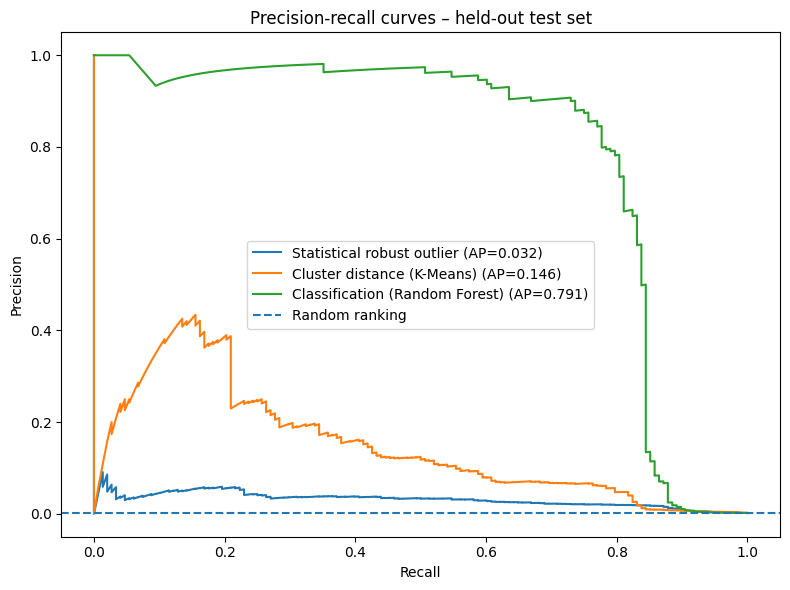

In [12]:
plt.figure(figsize=(8,6))
for name,s in scores.items():
    p,r,_=precision_recall_curve(yte,s)
    plt.plot(r,p,label=f"{name} (AP={average_precision_score(yte,s):.3f})")
plt.axhline(yte.mean(),ls="--",label="Random ranking")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall curves – held-out test set")
plt.legend(); plt.tight_layout(); plt.show()

The precision–recall curves compare the trade-off between the proportion of flagged transactions that are actually fraud (precision) and the proportion of all fraud cases detected (recall). The Random Forest curve is substantially above the two anomaly-score curves over much of the range, consistent with its much higher Average Precision. The dashed reference line represents random-ranking precision at the test-set fraud prevalence. The graph demonstrates why the supervised classifier is the strongest choice when the aim is to prioritise a limited investigation queue.

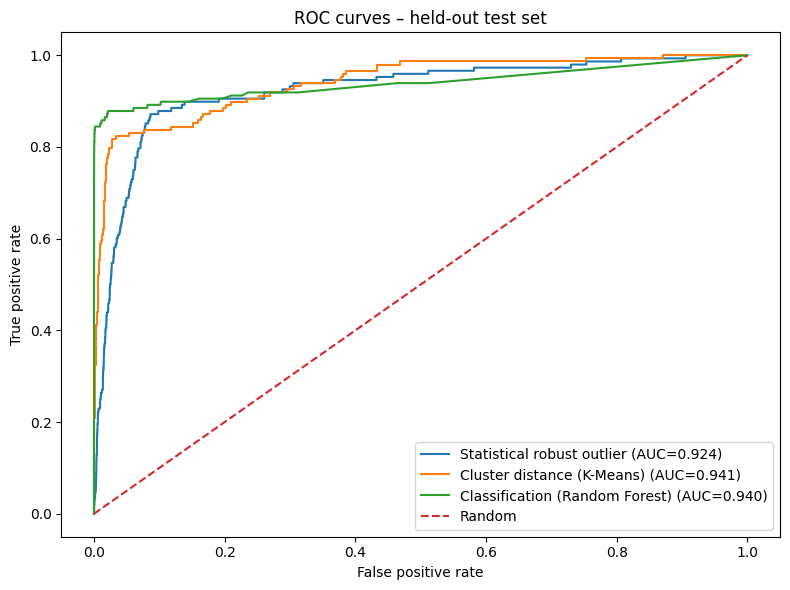

In [13]:
plt.figure(figsize=(8,6))
for name,s in scores.items():
    fpr,tpr,_=roc_curve(yte,s)
    plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(yte,s):.3f})")
plt.plot([0,1],[0,1],"--",label="Random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves – held-out test set"); plt.legend(); plt.tight_layout(); plt.show()

The ROC curve plots true-positive rate against false-positive rate. All three curves are well above the random diagonal, indicating ranking ability. K-Means has the largest ROC-AUC (0.94108), followed closely by Random Forest (0.93992), then the robust statistical baseline (0.92398). However, ROC-AUC does not directly show how many false alarms occur among the highest-ranked transactions when fraud is extremely rare; it should therefore be read alongside the precision–recall results.

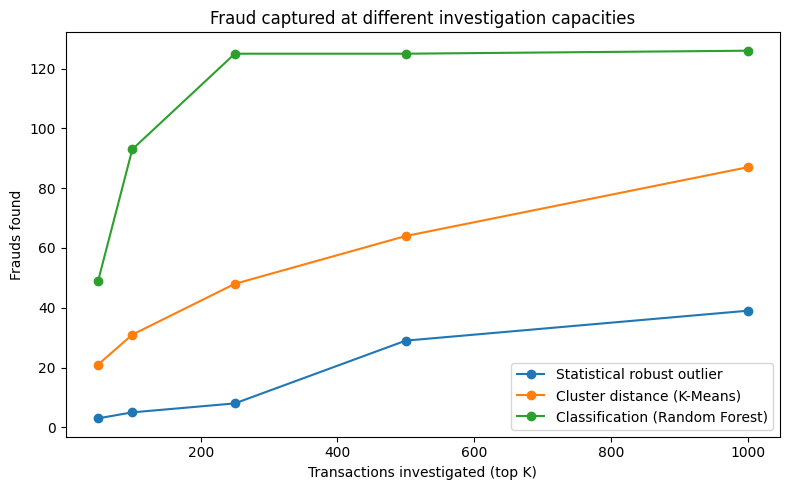

In [14]:
fig,ax=plt.subplots(figsize=(8,5))
for name in scores:
    z=topk[topk.method==name]
    ax.plot(z.K,z.frauds_found,marker="o",label=name)
ax.set_xlabel("Transactions investigated (top K)"); ax.set_ylabel("Frauds found")
ax.set_title("Fraud captured at different investigation capacities")
ax.legend(); plt.tight_layout(); plt.show()

This graph asks how many fraud cases are found when investigators review only the top K highest-scored transactions. At K = 50, Random Forest identifies 49 fraud cases (precision@50 = 0.980). At K = 100 it identifies 93 (precision@100 = 0.930), and at K = 250 it identifies 125 (precision@250 = 0.500). Its recall reaches 0.8446 by K = 250. This makes the model particularly useful when investigation capacity is limited. The number of frauds found by each method is not a fixed model property; it depends on the chosen K and ranking scores.

## 8. Threshold illustration and feature importance
Ranking is the main objective. A 0.5 probability threshold is shown only as an illustration; it is not claimed to be an optimal operational threshold. Thresholds should be selected using a separate validation set and explicit costs of missed fraud, false alarms and investigator time.

Random Forest impurity-based feature importance is reported as a descriptive diagnostic. Since `V1`–`V28` are anonymised PCA components, importance cannot be translated into original merchant or customer characteristics and should not be interpreted causally.

In [15]:
pred=(class_scores>=0.5).astype(int)
display(pd.DataFrame(confusion_matrix(yte,pred,labels=[0,1]),
    index=["Actual legitimate","Actual fraud"],
    columns=["Predicted legitimate","Predicted fraud"]))
print(classification_report(yte,pred,digits=4,zero_division=0))

,Predicted legitimate,Predicted fraud
Actual legitimate,85274,21
Actual fraud,33,115


              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997     85295
           1     0.8456    0.7770    0.8099       148

    accuracy                         0.9994     85443
   macro avg     0.9226    0.8884    0.9048     85443
weighted avg     0.9993    0.9994    0.9994     85443



,impurity importance
V14,0.217328
V4,0.128404
V10,0.119939
V17,0.109174
V3,0.065397
V12,0.061824
V11,0.053315
V16,0.045050
V2,0.029234
V7,0.020562


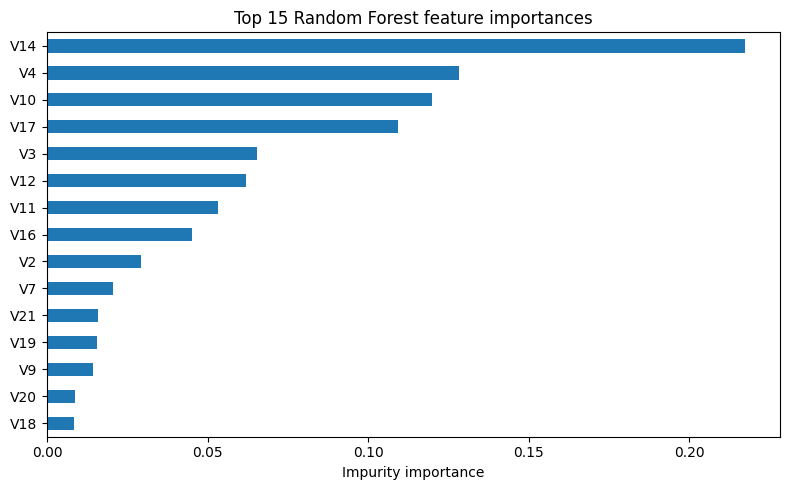

In [16]:
imp=pd.Series(rf.feature_importances_,index=feature_cols).sort_values(ascending=False)
display(imp.head(15).to_frame("impurity importance"))
imp.head(15).sort_values().plot(kind="barh",figsize=(8,5),title="Top 15 Random Forest feature importances")
plt.xlabel("Impurity importance"); plt.tight_layout(); plt.show()

V14 has the largest reported importance (0.2173), followed by V4 (0.1284), V10 (0.1199) and V17 (0.1092). These values describe how much the fitted forest used the anonymised components to split the training data. Because V1–V28 are anonymised PCA components, the ranking cannot be translated into original merchant, customer or transaction characteristics, and it should not be interpreted as causal evidence.

## 9. Why an unusual transaction is not necessarily fraudulent
Anomaly detection identifies observations that differ from a learned statistical or behavioural pattern. Fraud detection seeks transactions that are unauthorised or deceptive. These concepts overlap, but they are not equivalent.

Legitimate unusual transactions may include a large purchase for travel or medical expenses, a purchase in a new country because the cardholder is travelling, a one-off seasonal purchase, or an unusual transaction by a legitimate merchant. Conversely, fraud can be deliberately small or can imitate the cardholder's normal pattern and therefore may not appear statistically extreme.

An anomaly score is consequently a signal for review, not proof of fraud. A high false-positive rate can inconvenience legitimate customers and waste investigator time. Final decisions should combine risk scores with transaction context, authentication signals, customer history and human review.

## 10. Critical comparison
- **Robust statistical baseline:** transparent and inexpensive, but independent feature deviations do not capture complex interactions and the maximum score can be driven by one variable.
- **Cluster-based K-Means:** learns multiple legitimate patterns without fraud labels and flags transactions far from learned centroids. It is sensitive to scaling and the number of clusters; unusual legitimate activity can be flagged.
- **Classification-based Random Forest:** learns from known fraud examples and can capture nonlinear relationships. It requires representative labels, is affected by the small number of fraud cases and may fail on new fraud strategies.

The most useful approach depends on investigation capacity. Compare Average Precision and precision/recall at realistic K values, not accuracy alone. A high ROC-AUC does not guarantee high precision among the first cases investigated.

## 11. Limitations and responsible application
1. The dataset covers only two days in September 2013 and may not represent current transaction behaviour.
2. The original meanings of `V1`–`V28` are unavailable, restricting business interpretation.
3. Customer history, merchant identity, location, authentication outcome and chargeback details are not supplied.
4. The classifier learns only from fraud patterns represented in the labelled training sample.
5. The small fraud count makes evaluation uncertain and sensitive to individual cases.
6. A stratified random split was used to preserve rare events; a time-ordered split would better simulate deployment on future transactions.
7. Fraud patterns and normal behaviour change over time, requiring drift monitoring and periodic validation.
8. Model scores should prioritise human investigation, not automatically accuse customers or trigger punitive action without a separately validated policy.

Future work should use time-based validation, calibrated risk scores, cost-sensitive threshold selection, additional contextual variables and ongoing model monitoring.

## 12. Conclusion
This project compared a robust statistical outlier baseline, an unsupervised cluster-distance score and a supervised Random Forest classifier. The models were evaluated on a held-out test set whose labels were not used for fitting, using Average Precision, ROC-AUC, precision/recall at investigation-capacity cut-offs and precision-recall curves.

The key operational question is how many fraud cases each method places near the top of the investigation queue. A transaction that is unusual is not necessarily fraudulent; therefore, the detector should be used to prioritise review, with human investigation and contextual evidence supporting decisions.

## References and attribution
- Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432.
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining*, 226–231.

**Software:** Python, pandas, NumPy, Matplotlib and scikit-learn.